# TP1 - Analyse de jeu données 

---
Objectifs :
    
    - savoir importer des Fichiers csv
    - manipuler un notebook
    - savoir manipuler un dataframe et notammant la librairie pandas
    éléments associés: http://www.python-simple.com/python-pandas/tri-dataframes.php?word=dataframe
    - savoir manipuler un vecteur et notamment la librairie numpy
    éléments associés: http://www.python-simple.com/python-numpy/creation-numpy.php
    - savoir analyser des statistiques   
---

Veuillez compléter les champs vide (...) autant que nécessaire.

Habituez-vous à écrire en **markdown.** Ceci sera votre copie à rendre sur Moodle.

Nom : **Patron**

Prénom : **Antoine**

Groupe TP : **1**
    
Pour chaque question, faire une cellule **code** réponse et une cellule **markdown** pour formaliser une réponse de façon littéraire.

Pour chaque représentation, **améliorer vos figures**
par un titre général et des axes notamment et des annotations
Aide graphique : https://matplotlib.org/tutorials/introductory/pyplot.html


## Etude de cas semi-guidée

Dans cette étude, nous allons tout d'abord charger des données issues d'un fichier csv et importer les librairies nécessaires au demande. Ce fichier sera placé au même niveau que le notebook. 

Toutes les fonctions nécessaires vous ont été fournies dans le cours.

N'oubliez pas d'analyser les résultats mais aussi les paramètres des fonctions utilisées.


In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec # Alignments 

import seaborn as sns # theme & dataset
print(f"Matplotlib Version : {mpl.__version__}")
print(f"Seaborn Version : {sns.__version__}")

# for visualization samples
import pandas as pd

df = pd.read_csv("df.cercles.csv")

Matplotlib Version : 3.8.0
Seaborn Version : 0.12.2


Q11. Quelle est la taille des données?

In [2]:
df.shape


(631, 3)

Exemple de réponse litterale à compléter : Ce jeu de données contient **631** observations décrites par **3** variables. 

La fonction **shape** permet de récupérer la taille du tableau de données importées. Si elle a une seule dimension, cela peut-être liée au fait que le séparateur est différent de la fonction par défaut.

Rappel d'autre fonctions utiles pour visualiser si l'importation est correcte : tail, head, describe ...


Q12. Quels sont les noms des colonnes?



In [3]:
print(df.head(1))
print(df.columns)
print("nom de la premiere colonne :", df.columns[0])

          x         y  label
0 -0.567295 -0.025168      3
Index(['x', 'y', 'label'], dtype='object')
nom de la premiere colonne : x


Nous disposons d'une colonne nommée **x**, la seconde **y** et la dernière **label**

Q13- Quelle est la valeur de la 3eme colonne, 10eme ligne?

In [4]:
# corriger les valeurs par rapport à la demande
# en python le premier indice est zéro
df.iloc[9,2]

1

Le chiffre qui correspond au croisement de la 10ème ligne et 3ère colonne du dataframe est 1.
On se rappellera que la fonction iloc prend en argument des entiers (iloc **loc**ation by **i**nteger).

Q14 - Donner l'ensemble des valeurs de la 4eme ligne?

In [5]:
### à vous d'écrire le code associé
# etudier df.iloc[0,:]
# etudier df.iloc[:,0]
# etudier df.iloc[0:4:2,0]
print(df.iloc[0,:])
print("----------")
print(df.iloc[:,0])
print("----------")
print(df.iloc[0:4:2,0])

#Recuperation des valeurs de la quatrieme ligne
print("----------")
print(df.iloc[4,:])

x       -0.567295
y       -0.025168
label    3.000000
Name: 0, dtype: float64
----------
0     -0.567295
1      0.244930
2     -0.050888
3     -0.479755
4     -0.100310
         ...   
626   -0.372189
627   -0.083580
628   -0.369343
629   -0.174904
630   -0.564438
Name: x, Length: 631, dtype: float64
----------
0   -0.567295
2   -0.050888
Name: x, dtype: float64
----------
x       -0.100310
y        0.104597
label    2.000000
Name: 4, dtype: float64


La ligne de code df.iloc[0,:] permet de recuperer toutes les colonones de la ligne donnée.</br>
df.iloc[:,0] permet quand a elle de recuperer toutes les valeures d'une colone donnée.</br>
Enfin, df.iloc[0:4:2,0] permet de recuperer les valeur des lignes a partir de 0, jusqu'a la ligne 4 (exclue) avec un pas de 2, pour une colone donnée</br></br>
Pour récuperer l'ensemble des valeurs de la quatrieme ligne, on peut donc utiliser l'instruction df.iloc[4,:]. On obtient alors pour x -0.100310, 0.104597 pour y et 2 pour le label.

Q15- Que peut-on dire de la répartition des labels ? donner une représentation pertinente montrant cette répartition.

{1: 287, 2: 144, 3: 200}
{1: 45.48335974643423, 2: 22.820919175911254, 3: 31.695721077654518}
label
1    287
3    200
2    144
Name: count, dtype: int64


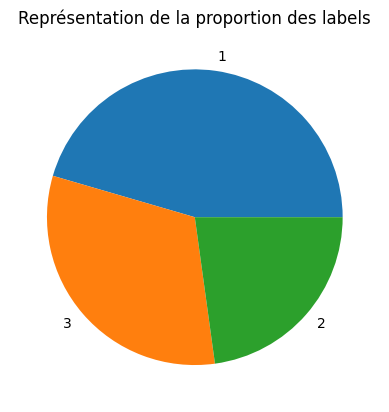

In [6]:
### à vous d'écrire le code associé, etudiez les propositions ci-dessous et les différents types des variables
comptage = df.groupby('label').size().to_dict()
total = sum(comptage.values())
proportion = {key: 100 *value / total for key, value in comptage.items()}

print(comptage)
print(proportion)

print(df["label"].value_counts())


plt.pie(df.label.value_counts(),labels=df.label.value_counts().index)
plt.title("Représentation de la proportion des labels")
plt.show()


On peut observer que les labels ne sont pas repartis de maniere equitable, avec une presence plus importante de labels de la valeur 1 par raport au autres.</br>
Cela pourrait entrainer un sous apprentissage des labels 2 et 3.

Q16- Afficher les valeurs de la 1ere colonne par un graphe dont l'axe des abscisses est le numéro de la ligne.  

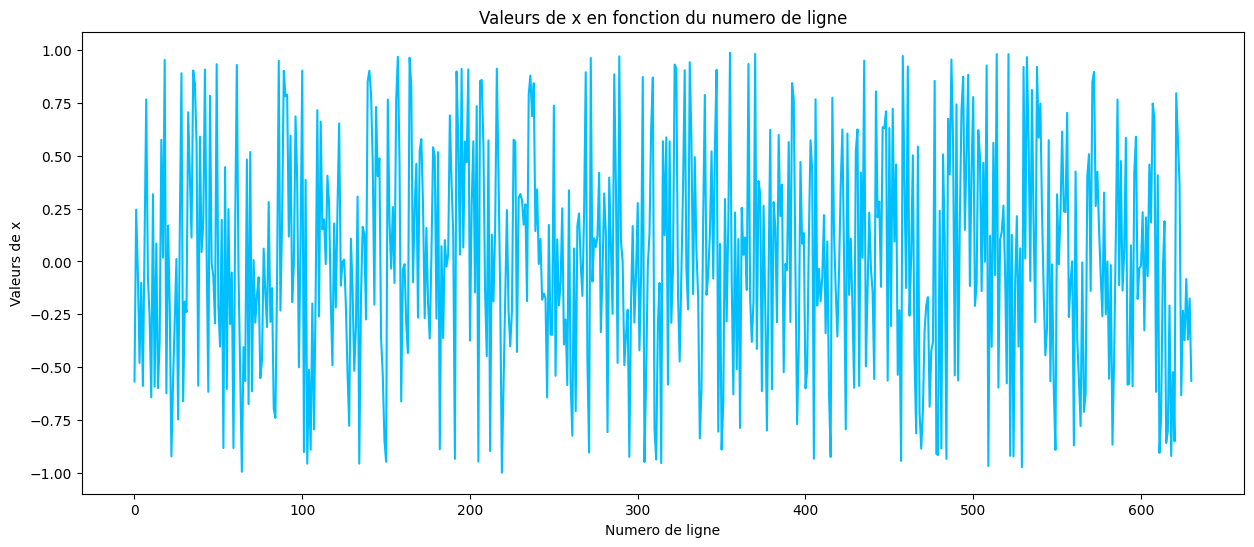

In [7]:
### à vous d'écrire le code associé, nommer votre graphique et renommer ses axes
import matplotlib.pyplot as plt
x = df['x']
plt.figure(figsize=(15,6))
plt.plot(x,color="deepskyblue")
plt.xlabel("Numero de ligne")
plt.ylabel("Valeurs de x")
plt.title("Valeurs de x en fonction du numero de ligne")
plt.show()

Q17- Calculer les statistiques de chaque variable. 


In [8]:
### à vous d'écrire le code associé, nommer votre graphique et renommer ses axes
# Moyenne
print(df[["x","y"]].describe())

                x           y
count  631.000000  631.000000
mean     0.020122    0.016420
std      0.520465    0.515919
min     -0.998235   -0.991554
25%     -0.352109   -0.348160
50%     -0.004883   -0.005213
75%      0.420124    0.431033
max      0.986104    0.994370


On peut observer que les series x et y sont relativement proches l'une de l'autre.

Q18- Afficher la boite à moustache de la variable x indépendamment des autres variables. La valeur médiane est-elle éloignée de la moyenne?

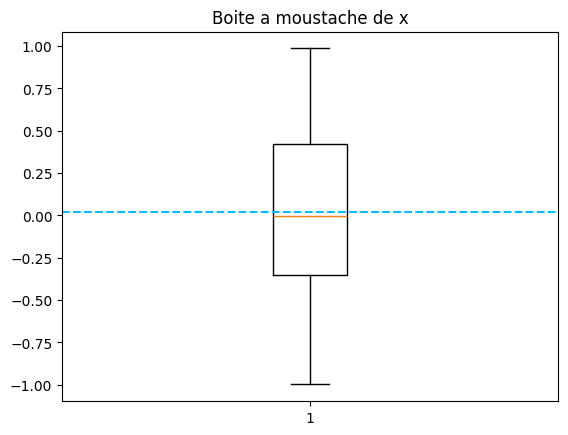

In [9]:
### à vous d'écrire le code associé, donner une représentation horizontale. 
# ajouter sur le graphe la moyenne
# et une legende
plt.boxplot(df.x); 
plt.title("Boite a moustache de x")
plt.axhline(df["x"].mean(),color="deepskyblue",linestyle='--')
plt.show()

On peut observer sur la boite a moustache que la moyenne est plutot proche de la mediane, et que les quantile sont plus ou moins a equi-distance de la mediane.</br>
Cela pourrait laisser entendre que la variable x suit une distribution gaussienne.

Q19- La distribution de la variable x permet-elle d'identifier un nombre de structures particulières?

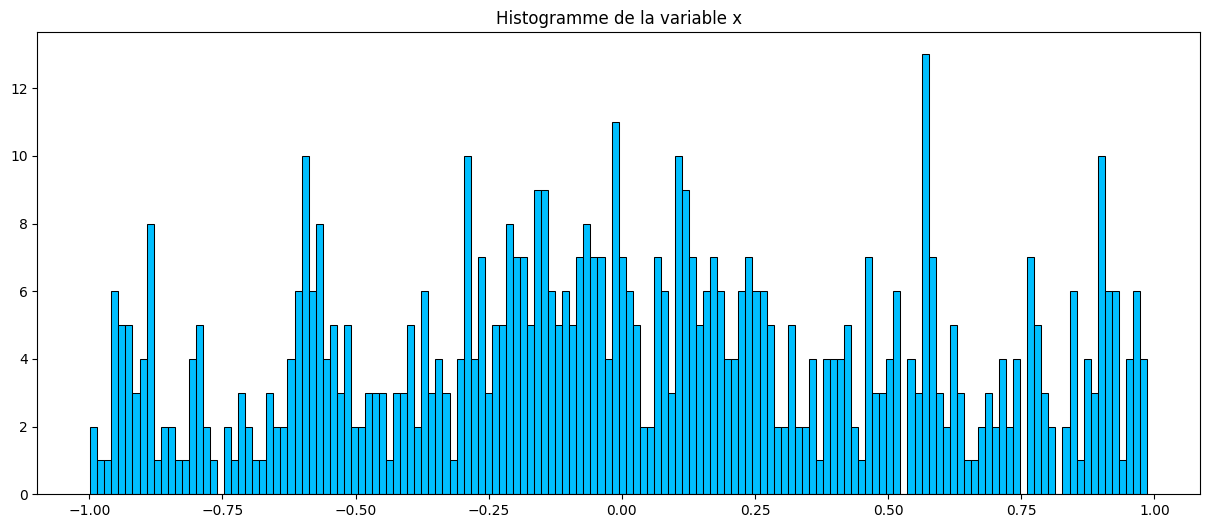

In [29]:
### à vous d'écrire le code associé
# la boite à moustache permet parfois de répondre directement
# la deuxième possibilité est de regarder l'histogramme

plt.figure(figsize=(15,6))
plt.hist(x,color="deepskyblue",edgecolor='black', linewidth=0.75,bins=150) 
plt.title("Histogramme de la variable x")
plt.show()

Contrairement a ce qu'aurait pus laisser entendre la boite a moustache, l'analyse de l'histograme montre que la distribution de x n'est pas gaussienne

Q20- Etudier maintenant la représentation par paire de variables, est-il possible d'identifier des structures particulières?


/home/antoine/.local/lib/python3.10/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/home/antoine/.local/lib/python3.10/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/home/antoine/.local/lib/python3.10/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/home/antoine/.local/lib/python3.10/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) inst

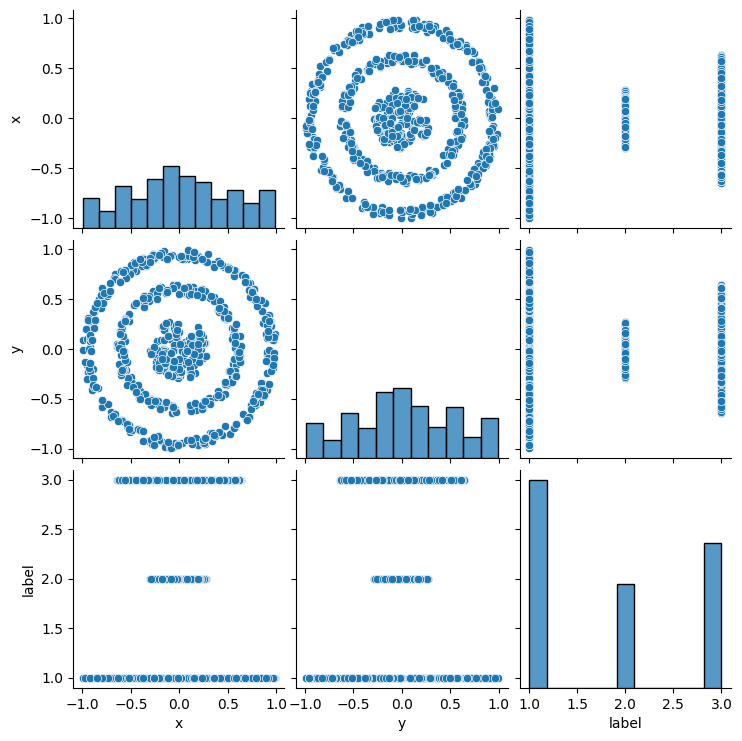

In [11]:
### à vous d'écrire le code associé
import seaborn as sns
sns.pairplot(df[["x", "y", "label"]])

On peut observer sur la representation par paires de variables qu'il n'est pas possible de retrouver le label de x ou y de maniere lineaire. On peut egalement voir que le label 1 correspond au cercle exterieur, le 2 au cercle interieur, et le 3 au cercle intermediaire.

Q21- Analysez maintenant pour les données du fichier df.serpentins.csv si il est possible d'identifier les structures ?

Ce dataframe contient 1500 lignes, et 3 colones.
----------
          x         y  label
0  0.341768  0.599915      1
1  1.085804 -0.507560      1
2  0.311245  0.682019      1
3  1.113309 -0.440515      1
4 -1.735649  0.034266      1
5 -0.209052 -0.458555      1
6  0.029496  0.034901      1
7  1.521813 -0.377603      1
8 -0.789416 -0.290035      1
9  1.006793 -0.310872      1


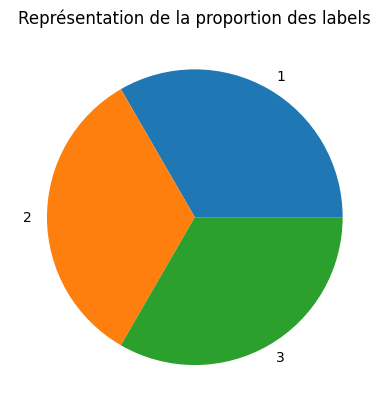

                  x             y
count  1.500000e+03  1.500000e+03
mean  -5.625130e-17  1.136868e-16
std    1.000000e+00  1.000000e+00
min   -1.750177e+00 -1.868760e+00
25%   -8.479669e-01 -6.886051e-01
50%   -3.827615e-03  5.052067e-02
75%    8.850596e-01  6.764816e-01
max    1.715530e+00  1.898686e+00


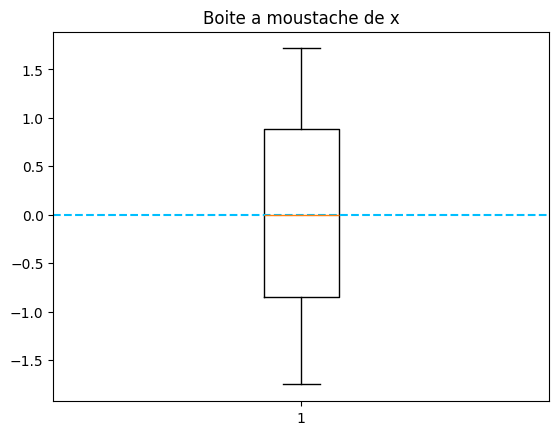

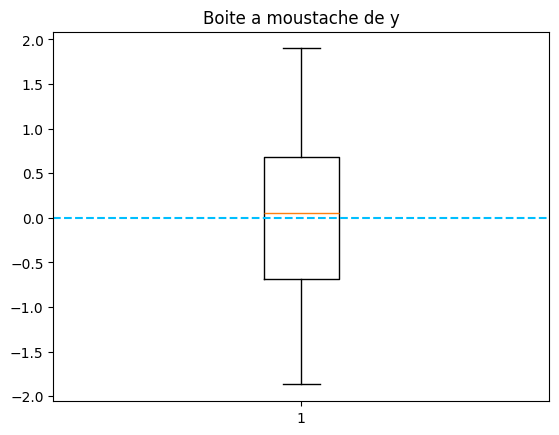

In [12]:
### à vous d'écrire le code associé
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

df = pd.read_csv("df.serpentins.csv")

print("Ce dataframe contient",df.shape[0],"lignes, et",df.shape[1],"colones.")
print("----------")
print(df.head(10))

plt.pie(df.label.value_counts(),labels=df.label.value_counts().index)
plt.title("Représentation de la proportion des labels")
plt.show()

print(df[["x","y"]].describe())

plt.boxplot(df.x); 
plt.title("Boite a moustache de x")
plt.axhline(df["x"].mean(),color="deepskyblue",linestyle='--')
plt.show()

plt.boxplot(df.y); 
plt.title("Boite a moustache de y")
plt.axhline(df["y"].mean(),color="deepskyblue",linestyle='--')
plt.show()

/home/antoine/.local/lib/python3.10/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/home/antoine/.local/lib/python3.10/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/home/antoine/.local/lib/python3.10/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/home/antoine/.local/lib/python3.10/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) inst

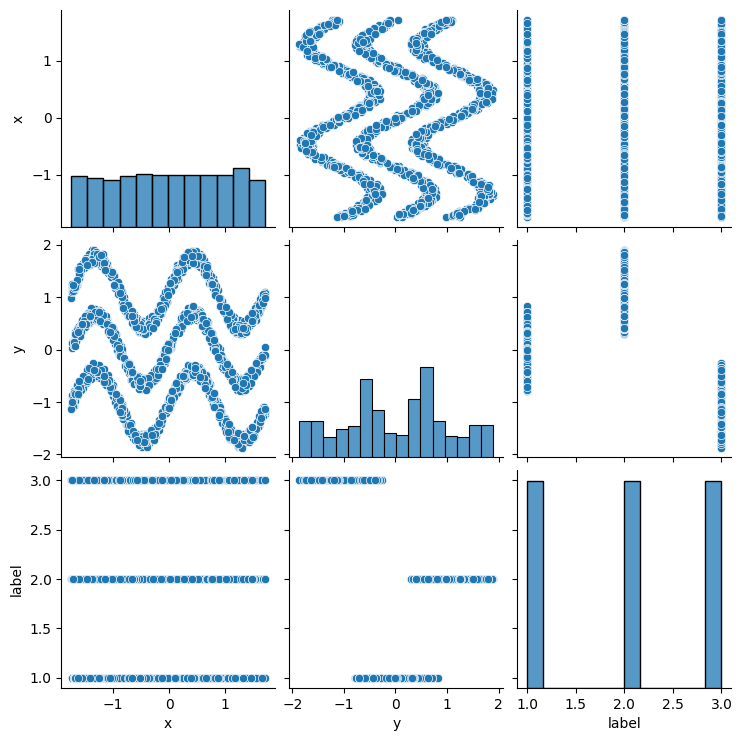

In [13]:
sns.pairplot(df[["x", "y", "label"]])

On peut observer que ce dataframe comporte une structure en triple vague. Celle ci pourrait permetre de retrouver le label en fonction de x et y grace a des sinusoidale presantant les bonnes caracteristiques.

---
## Etude de cas non guidée 

Le fichier BergenData est un extrait des mesures collectées sur la morue de 2017 et 2018 en vue d'estimer la taille des filets des poissons à recommander pour assurer une pêche durable. Pour cela ils doivent estimer si le poisson a dépassé sa phase de reproduction et donner une longueur minimale à respecter. 
Le poisson étudié, la morue, est mature sexuellement entre 2 et 7 ans, 5-6 ans pour la femelle.  

Q22. Importer le jeu de données BergenData.csv et retirer le paramètre *id* qui ne sert pas à l'étude.

Q23. Etudier la statique de chaque paramètre.

Q24. Etudier maintenant chacun des paramètres par rapport à l'âge.

Q25. Avons-nous la même quantité d'information par âge.

Q26. Est-il possible de construire une relation entre ces paramètres et l'age ? Analyser une solution par régression. 

Q27. Quelle longueur serait à recommander pour les filets de pêches ? 

Q28. BONUS. Présenter cela dans un dashboard

Voici une exemple de dashbord à écrire dans un fichier python (fic.py) et lancer-le en console : python3 ./fic.py

In [14]:
#fichier .py
import pandas as pd
import dash
from dash import Dash, html, dcc, callback, Output, Input
import plotly.express as px

# Charger les données (remplacez 'data.csv' par votre propre fichier de données)
df = pd.read_csv('df.serpentins.csv')

# Initialiser l'application Dash
app = dash.Dash(__name__)

# Mise en page de l'application Dash
app.layout = html.Div([
    html.H1("Visualisation de données"),
    dcc.Dropdown(
        id='pairplot-column',
        options=[{'label': col, 'value': col} for col in df.columns],
        multi=True,
        value=['col1', 'col2']  # Sélectionnez les colonnes par défaut ici
    ),
    dcc.Graph(id='pairplot-graph'),
    dcc.Dropdown(
        id='boxplot-column',
        options=[{'label': col, 'value': col} for col in df.columns],
        multi=False,
        value='x'  # Sélectionnez la colonne par défaut ici
    ),
    dcc.Graph(id='boxplot-graph')
])

# Callback pour générer les pairplots et les boîtes à moustaches
@app.callback(
    [Output('pairplot-graph', 'figure'),
     Output('boxplot-graph', 'figure')],
   [Input('pairplot-column', 'value'),
     Input('boxplot-column', 'value')]
)
def update_graphs(pairplot_columns, boxplot_column):
    pairplot_fig = None
    boxplot_fig = None

    if pairplot_columns:
        # Créer un pairplot à l'aide de Plotly Express
        pairplot_fig = px.scatter_matrix(df, dimensions=pairplot_columns, color='label')

    if boxplot_column:
        # Créer une boîte à moustaches à l'aide de Plotly Express
        boxplot_fig = px.box(df, x=boxplot_column)

    return pairplot_fig, boxplot_fig

# Exécuter l'application Dash
if __name__ == '__main__':
    app.run_server(debug=True)

ModuleNotFoundError: No module named 'dash'

In [16]:
#Question 22
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

df = pd.read_csv("BergenData.csv")

print("Ce dataframe contient",df.shape[0],"lignes, et",df.shape[1],"colones.")
print("----------")
print(df.head(3))

print("----------")
df=df.drop(columns="id")
print(df.head(3))

Ce dataframe contient 521 lignes, et 6 colones.
----------
   id   weight  length  liverweight  gonadweight   age
0   1  20700.0   132.0        0.528        2.300  14.0
1   2   1308.0    54.0        0.082        0.002   5.0
2   3   2730.0    72.0        0.046        0.039   7.0
----------
    weight  length  liverweight  gonadweight   age
0  20700.0   132.0        0.528        2.300  14.0
1   1308.0    54.0        0.082        0.002   5.0
2   2730.0    72.0        0.046        0.039   7.0


In [17]:
#Q23. Etudier la statique de chaque paramètre.
print(df.describe())

             weight      length  liverweight  gonadweight         age
count    521.000000  521.000000   521.000000   521.000000  521.000000
mean    5040.381958   76.446257     0.323173     0.467902    7.729367
std     4258.042421   19.735291     0.370868     0.823837    2.671373
min      495.000000   40.000000     0.007000     0.001000    3.000000
25%     2090.000000   62.000000     0.074000     0.009000    6.000000
50%     3660.000000   75.000000     0.170000     0.101000    7.000000
75%     6765.000000   90.000000     0.435000     0.464000    9.000000
max    23620.000000  132.000000     1.823000     5.240000   16.000000


##### Observations generales :
On peut observer que le nombre de valeurs est le meme pour chaque variable, il ne manque donc pas de données.

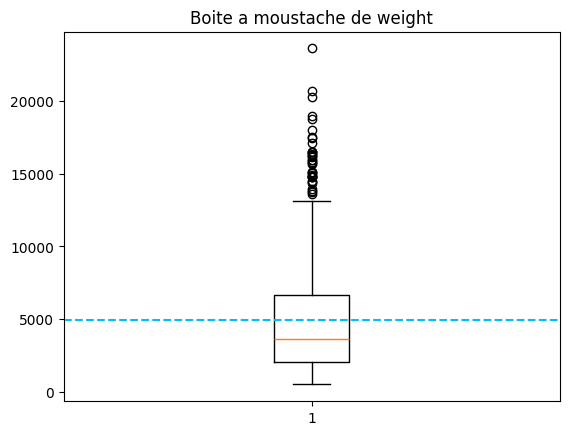

In [41]:
plt.boxplot(df.weight)
plt.title("Boite a moustache de weight")
plt.axhline(df["weight"].mean(),color="deepskyblue",linestyle='--')
plt.show()

##### Weight :
On peut observer un certain nombre de points en dehors de la boite a moustache, cepandant, il semble y avoir une certaine continuité dans leurs repartition. Il est donc peu probable qu'ils posent un probleme pour la suite. Par precaution on pourra supprimer les 3 plus grandes valeurs qui ce detachent du reste.
On peut egalement voir que la moyenne est significativement superieure a la mediane, et que les moustaches ne sont pas symetriques.
Dans le contexte de ce Dataframe, on pourait penser que le poid croit de maniere quadratique par rapport a l'age du poisson, mais cela ne peut etre confirmer pour le moment.

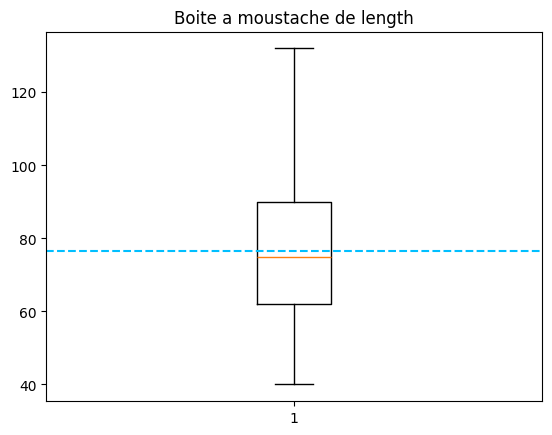

In [19]:
plt.boxplot(df.length)
plt.title("Boite a moustache de length")
plt.axhline(df["length"].mean(),color="deepskyblue",linestyle='--')
plt.show()

##### Length :
On peut dans un premier temp observer qu'il ne semble pas y avoir de données aberantes pour ce parametre. On peut egalement voir que la moyenne et la mediane sont relativement proches. Enfin, on peut voir que les moustache ne sont pas exactement de la meme longueure. Toujour dans le contexte de ce dataframe, on pourrait supposer que la taille croit de maniere logaritmique par rapport a l'age. Cepandant, comme pour le parametre precedant, il faudrat ou non confirmer cette observation avec d'autres outils.

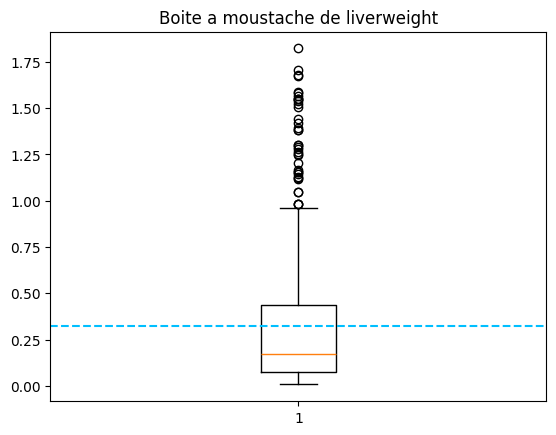

In [20]:
plt.boxplot(df.liverweight)
plt.title("Boite a moustache de liverweight")
plt.axhline(df["liverweight"].mean(),color="deepskyblue",linestyle='--')
plt.show()

##### Liverweight :
On peut remarquer que la repartition de ce parametre est tres semblable a celle de weight. Comme pour celui ci, on pourrait supprimer les 3 valeurs les plus extremes. On peut egalement supposer que ces valeurs sont corrélées. Il faudrat verifier cette suposition par la suite.

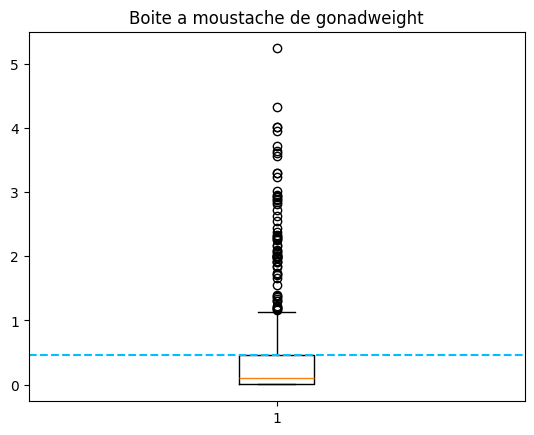

In [21]:
plt.boxplot(df.gonadweight)
plt.title("Boite a moustache de gonadweight")
plt.axhline(df["gonadweight"].mean(),color="deepskyblue",linestyle='--')
plt.show()

##### Gonadweight :
On peut observer la presence d'un certain nombre de valeurs en dehors du champ de la boite a moustache, avec une a deux valeures particulierement extreme. On pourrait supprimer ces valeures par precaution. On peut egalement observer que la moyenne est tres eloignee de la mediane.

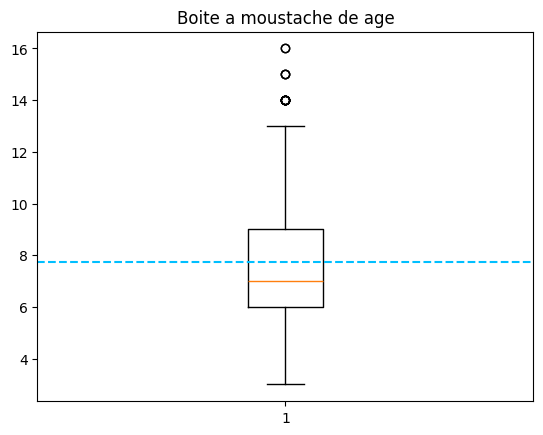

In [22]:
plt.boxplot(df.age)
plt.title("Boite a moustache de age")
plt.axhline(df["age"].mean(),color="deepskyblue",linestyle='--')
plt.show()

##### Age :
On peut observer qu'il y a quelques poissons dont les ages sont en dehors du champ de la boites a mousatches, on peut supposer qu'ils sont a l'origine des valeurs hor champs des autres parametres. Ils pourrait etre utile de les supprimer pour ne pas impacter les autres outils utilise. On peut egalement observer que la moyenne est legerement superieure a la mediane.

In [23]:
# Suppresion des valeures extremes
ext=np.where(df['age']>=15)
for i in ext:
    df.drop(i,inplace=True)
print(df.shape)

(516, 5)


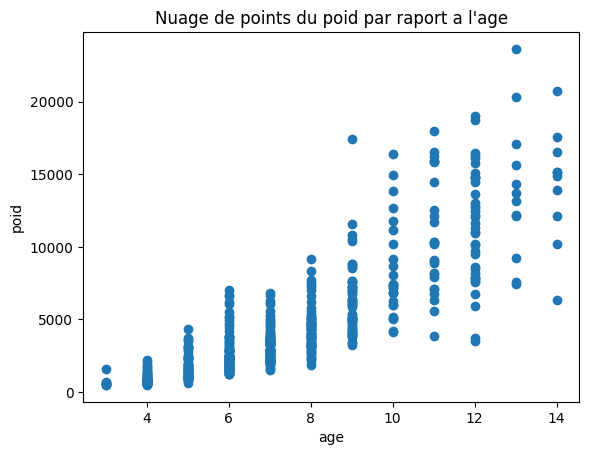

In [42]:
# Q24. Etudier maintenant chacun des paramètres par rapport à l'âge.
plt.scatter(df.age,df.weight)
plt.title('Nuage de points du poid par raport a l\'age')
plt.xlabel('age')
plt.ylabel('poid')
plt.show()

On peut observer qu'a mesure que l'age progresse, il est de plus en plus difficile de la retrouver par rapport au poid, car l'ecart entre le min et le max du poid pour chaque age est de plus en plus eleve.

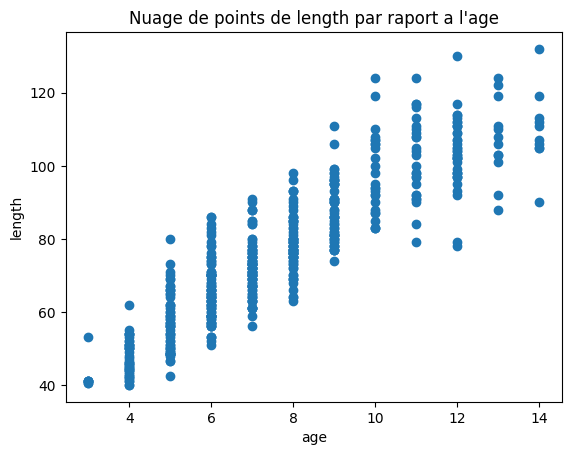

In [25]:
plt.scatter(df.age,df.length)
plt.title('Nuage de points de length par raport a l\'age')
plt.xlabel('age')
plt.ylabel('length')
plt.show()

On peut observer que l'ecart entre le min et le max de length par rapport a l'age est relativement constant, particulierement jusqu'a 10/11 ans, cepandant, il parait trop important pour pouvoir determiner l'age en fonction du poid.

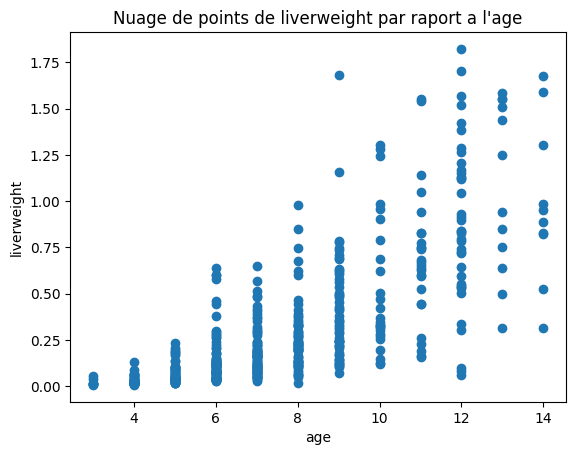

In [28]:
plt.scatter(df.age,df.liverweight)
plt.title('Nuage de points de liverweight par raport a l\'age')
plt.xlabel('age')
plt.ylabel('liverweight')
plt.show()

La repartition de liverweight par rapport a l'age ne permet pas d'identifier celui-ci grace a ce parametre.

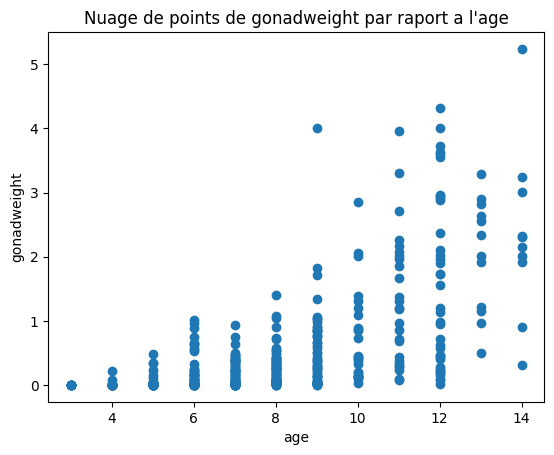

In [27]:
plt.scatter(df.age,df.gonadweight)
plt.title('Nuage de points de gonadweight par raport a l\'age')
plt.xlabel('age')
plt.ylabel('gonadweight')
plt.show()

La repartition de liverweight par rapport a l'age ne permet pas d'identifier celui-ci grace a ce parametre.

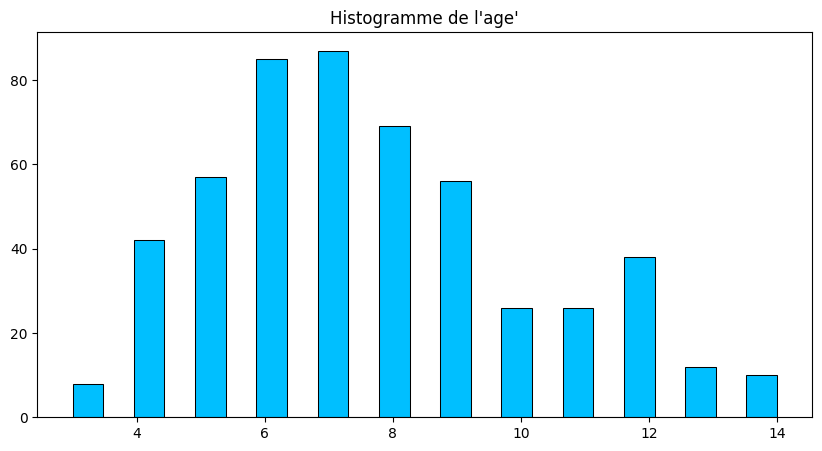

In [40]:
# Q25. Avons-nous la même quantité d'information par âge.
plt.figure(figsize=(10,5))
plt.hist(df.age,color="deepskyblue",edgecolor='black', linewidth=0.75,bins=23) 
plt.title("Histogramme de l'age'")
plt.show()

On peut observer grace a l'histogramme qu'une grande partie des données ne concerne qu'une petite tranche d'age (de 6 a 8 ans environ) et l'on dispose de tres peu d'information pour les ages inferieurs a 4 ans et superieurs a 9 ans. Il est probable que cette mauvaise repartition puisse causer des problemes par la suite.

##### Q26. Est-il possible de construire une relation entre ces paramètres et l'age ? Analyser une solution par régression. 
